# v19.5 Global Soil Moisture — Full Error Analysis & Visualization

This notebook compares the two completed v19.5 models:

- **`location_history`** — environmental features plus station/location history.
- **`environment_only`** — environmental features without location-history inputs.

It reads the already-exported predictions from the two directories in `UG_SM`. It **does not retrain models or rerun inference**. It uses DuckDB to aggregate directly from Parquet so the large prediction tables are not loaded wholesale into pandas.

## Before running

1. Put this notebook in your local `UG_SM` directory (the same directory that contains the two extracted export folders).
2. Make sure these folders are present:
   - `error_analysis_export_v19_5_location_history/`
   - `error_analysis_export_v19_5_environment_only/`
3. Run the cells from top to bottom.

Required Python packages: `duckdb`, `pandas`, `numpy`, `pyarrow`, and `matplotlib`. Install missing packages in your environment with:

```bash
python -m pip install duckdb pandas numpy pyarrow matplotlib
```

The notebook saves tables, plots, an audit report, and a compact analysis database in `error_analysis_results_v19_5/`.

> **Important interpretation:** the train predictions are predictions from the final selected checkpoint in evaluation/inference mode on the training split. They are useful for diagnosing fit, but are not the model's online predictions at the moment each training observation was learned. The held-out test results are the primary estimate of generalisation.

In [1]:
# 1. Imports and user settings
from pathlib import Path
import json, math, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import duckdb
except ImportError as exc:
    raise ImportError(
        "DuckDB is required for memory-conscious analysis. Install it with: "
        "python -m pip install duckdb"
    ) from exc

# Usually the notebook is opened with UG_SM as the working directory.
BASE_DIR = Path.cwd().resolve()
LOCATION_DIR_NAME = "error_analysis_export_v19_5_location_history"
ENVIRONMENT_DIR_NAME = "error_analysis_export_v19_5_environment_only"

# Keep station summaries from becoming noisy. Lower this to include smaller stations.
MIN_STATION_ROWS = 10
# Max rows pulled into pandas for scatter/histogram plots (aggregations still use all rows).
PLOT_SAMPLE_PER_SPLIT = 60000
# Approximate global grid size for spatial error summaries, in degrees.
SPATIAL_GRID_DEGREES = 2.0
# Optional: set a DuckDB memory cap such as "6GB". None lets DuckDB use its default.
DUCKDB_MEMORY_LIMIT = None

OUTPUT_DIR = BASE_DIR / "error_analysis_results_v19_5"
PLOTS_DIR = OUTPUT_DIR / "plots"
TABLES_DIR = OUTPUT_DIR / "tables"
for _p in (OUTPUT_DIR, PLOTS_DIR, TABLES_DIR):
    _p.mkdir(parents=True, exist_ok=True)

print("Working directory:", BASE_DIR)
print("Analysis outputs:", OUTPUT_DIR)

Working directory: /home/mayur/Code/UG_SM
Analysis outputs: /home/mayur/Code/UG_SM/error_analysis_results_v19_5


In [2]:
# 2. Locate and validate both export directories

def locate_export_dir(folder_name: str) -> Path:
    direct = BASE_DIR / folder_name
    if (direct / "predictions" / "train_predictions.parquet").is_file():
        return direct
    # Handles the common case where the archive was extracted one directory deeper.
    matches = []
    # Search only one directory level down; avoid crawling the large model/cache tree.
    for candidate in BASE_DIR.glob(f"*/{folder_name}"):
        if (candidate / "predictions" / "train_predictions.parquet").is_file():
            matches.append(candidate)
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        raise RuntimeError(
            f"Found multiple valid {folder_name} directories:\n" +
            "\n".join(str(x) for x in matches) +
            "\nSet the corresponding *_EXPORT_DIR variable manually in this cell."
        )
    raise FileNotFoundError(
        f"Could not find {folder_name}/predictions/train_predictions.parquet.\n"
        f"Expected it under {BASE_DIR}. Move this notebook into UG_SM or edit BASE_DIR."
    )

LOCATION_EXPORT_DIR = locate_export_dir(LOCATION_DIR_NAME)
ENVIRONMENT_EXPORT_DIR = locate_export_dir(ENVIRONMENT_DIR_NAME)
EXPORT_DIRS = {
    "location_history": LOCATION_EXPORT_DIR,
    "environment_only": ENVIRONMENT_EXPORT_DIR,
}

for mode, folder in EXPORT_DIRS.items():
    print(f"\n{mode}: {folder}")
    for required in [
        folder / "predictions" / "train_predictions.parquet",
        folder / "predictions" / "test_predictions.parquet",
        folder / "model_config.json",
        folder / "final_metrics.json",
    ]:
        if not required.is_file():
            raise FileNotFoundError(f"Required export file missing for {mode}: {required}")
    cfg = json.loads((folder / "model_config.json").read_text(encoding="utf-8"))
    print("  target_mode:", cfg.get("target_mode"), "| backbone:", cfg.get("temporal_backbone"))
    for split in ("train", "test"):
        f = folder / "predictions" / f"{split}_predictions.parquet"
        print(f"  {split:5s}: {f.stat().st_size / (1024**3):.3f} GiB")

# Check that both exports describe the same target definition.
CONFIGS = {m: json.loads((p / "model_config.json").read_text(encoding="utf-8"))
           for m, p in EXPORT_DIRS.items()}
if CONFIGS["location_history"].get("target_mode") != CONFIGS["environment_only"].get("target_mode"):
    raise ValueError("The exports use different target_mode values; comparing their scores would not be valid.")
TARGET_MODE = CONFIGS["location_history"].get("target_mode")
print("\nShared target_mode:", TARGET_MODE)


location_history: /home/mayur/Code/UG_SM/error_analysis_export_v19_5_location_history
  target_mode: direct | backbone: tcn
  train: 0.164 GiB
  test : 0.075 GiB

environment_only: /home/mayur/Code/UG_SM/error_analysis_export_v19_5_environment_only
  target_mode: direct | backbone: tcn
  train: 0.182 GiB
  test : 0.053 GiB

Shared target_mode: direct


In [3]:
# 3. Open prediction Parquet files as DuckDB views (no full-table pandas load)
DB = duckdb.connect(database=":memory:")
DB.execute("SET threads = 4")
DUCKDB_TEMP_DIR = OUTPUT_DIR / "duckdb_tmp"
DUCKDB_TEMP_DIR.mkdir(parents=True, exist_ok=True)
DB.execute(f"SET temp_directory = '{DUCKDB_TEMP_DIR.as_posix().replace(chr(39), chr(39)*2)}'")
if DUCKDB_MEMORY_LIMIT:
    DB.execute(f"SET memory_limit = '{DUCKDB_MEMORY_LIMIT}'")


def sql_string(value: str) -> str:
    return "'" + str(value).replace("'", "''") + "'"

VIEWS = {}
for mode, folder in EXPORT_DIRS.items():
    for split in ("train", "test"):
        view = f"{ 'lh' if mode == 'location_history' else 'eo' }_{split}"
        parquet_path = folder / "predictions" / f"{split}_predictions.parquet"
        DB.execute(f"CREATE OR REPLACE VIEW {view} AS SELECT * FROM read_parquet({sql_string(parquet_path.as_posix())})")
        VIEWS[(mode, split)] = view

REQUIRED_COLUMNS = {
    "sample_id", "network", "station_id", "station_key", "sample_date",
    "latitude", "longitude", "y_true_m3_m3", "prediction_m3_m3",
    "raw_prediction_m3_m3", "anchor_smap_m3_m3", "residual_m3_m3",
    "absolute_error_m3_m3", "squared_error_m3_m6", "raw_residual_m3_m3",
}
SCHEMAS = {}
for (mode, split), view in VIEWS.items():
    cols = {r[0] for r in DB.execute(f"DESCRIBE {view}").fetchall()}
    SCHEMAS[(mode, split)] = cols
    missing = sorted(REQUIRED_COLUMNS - cols)
    if missing:
        raise ValueError(f"{mode}/{split} prediction file is missing required columns: {missing}")
    n_rows, n_stations, d0, d1 = DB.execute(
        f"SELECT COUNT(*), COUNT(DISTINCT station_key), MIN(CAST(sample_date AS DATE)), "
        f"MAX(CAST(sample_date AS DATE)) FROM {view}"
    ).fetchone()
    print(f"{mode:17s} {split:5s}: {n_rows:>12,} rows | {n_stations:>7,} stations | {d0} to {d1}")

# A compact schema report makes it easy to audit exactly what was exported.
schema_report = []
for (mode, split), cols in SCHEMAS.items():
    schema_report.append({"task_mode": mode, "split": split, "columns": len(cols),
                          "has_SMAP": "SMAP" in cols, "has_target_quality_fields": "target_std_m3_m3" in cols})
schema_report = pd.DataFrame(schema_report)
display(schema_report)

location_history  train:    2,216,784 rows |   2,100 stations | 2015-04-01 to 2022-12-31
location_history  test :      905,248 rows |   1,028 stations | 2023-01-01 to 2026-10-03
environment_only  train:    2,544,038 rows |   1,758 stations | 2015-04-01 to 2026-10-03
environment_only  test :      644,716 rows |     444 stations | 2015-04-01 to 2026-10-03


,task_mode,split,columns,has_SMAP,has_target_quality_fields
0,location_history,train,32,True,True
1,location_history,test,32,True,True
2,environment_only,train,32,True,True
3,environment_only,test,32,True,True


## 1) Data and export integrity

The export code wrote `source_row_index` and verified that each model-loader target agrees with the corresponding manifest target before finalizing each Parquet file. This section performs independent checks on the local files: prediction counts, duplicate sample keys, missing numerical values, train/test date coverage, and the recorded-versus-recomputed metrics.

In [4]:
# 4. Row-level integrity checks and export metadata comparison
integrity_rows = []
for (mode, split), view in VIEWS.items():
    row = DB.execute(f"""
        SELECT
          COUNT(*) AS n_rows,
          COUNT(DISTINCT sample_id) AS n_distinct_sample_id,
          COUNT(DISTINCT station_key) AS n_stations,
          SUM(CASE WHEN y_true_m3_m3 IS NULL OR NOT isfinite(y_true_m3_m3) THEN 1 ELSE 0 END) AS bad_y,
          SUM(CASE WHEN prediction_m3_m3 IS NULL OR NOT isfinite(prediction_m3_m3) THEN 1 ELSE 0 END) AS bad_prediction,
          SUM(CASE WHEN residual_m3_m3 IS NULL OR NOT isfinite(residual_m3_m3) THEN 1 ELSE 0 END) AS bad_residual,
          SUM(CASE WHEN ABS((prediction_m3_m3 - y_true_m3_m3) - residual_m3_m3) > 1e-5 THEN 1 ELSE 0 END) AS residual_formula_mismatch,
          SUM(CASE WHEN ABS(ABS(residual_m3_m3) - absolute_error_m3_m3) > 1e-5 THEN 1 ELSE 0 END) AS abs_error_formula_mismatch,
          MIN(CAST(sample_date AS DATE)) AS min_date,
          MAX(CAST(sample_date AS DATE)) AS max_date
        FROM {view}
    """).df().iloc[0].to_dict()
    row.update(task_mode=mode, split=split)
    integrity_rows.append(row)
INTEGRITY = pd.DataFrame(integrity_rows)[[
    "task_mode", "split", "n_rows", "n_distinct_sample_id", "n_stations",
    "bad_y", "bad_prediction", "bad_residual", "residual_formula_mismatch",
    "abs_error_formula_mismatch", "min_date", "max_date"
]]
display(INTEGRITY)
INTEGRITY.to_csv(TABLES_DIR / "integrity_checks.csv", index=False)

if (INTEGRITY[["bad_y", "bad_prediction", "bad_residual", "residual_formula_mismatch", "abs_error_formula_mismatch"]].fillna(0).to_numpy() > 0).any():
    warnings.warn("At least one data-integrity check is non-zero. Inspect integrity_checks.csv before interpreting metrics.")

# Compare recomputed full-split metrics to the values written by the export cell.
def load_export_metrics(mode):
    return json.loads((EXPORT_DIRS[mode] / "final_metrics.json").read_text(encoding="utf-8"))
EXPORT_METRICS = {m: load_export_metrics(m) for m in EXPORT_DIRS}
print("\nCheckpoint metadata")
for mode, cfg in CONFIGS.items():
    print(f"{mode}: best_epoch={cfg.get('best_epoch')}, target_mode={cfg.get('target_mode')}, backbone={cfg.get('temporal_backbone')}")

,task_mode,split,n_rows,n_distinct_sample_id,n_stations,bad_y,bad_prediction,bad_residual,residual_formula_mismatch,abs_error_formula_mismatch,min_date,max_date
0,location_history,train,2216784,2216784,2100,0.0,0.0,0.0,0.0,0.0,2015-04-01,2022-12-31
1,location_history,test,905248,905248,1028,0.0,0.0,0.0,0.0,0.0,2023-01-01,2026-10-03
2,environment_only,train,2544038,2544038,1758,0.0,0.0,0.0,0.0,0.0,2015-04-01,2026-10-03
3,environment_only,test,644716,644716,444,0.0,0.0,0.0,0.0,0.0,2015-04-01,2026-10-03



Checkpoint metadata
location_history: best_epoch=79, target_mode=direct, backbone=tcn
environment_only: best_epoch=13, target_mode=direct, backbone=tcn


## 2) Overall performance — calibrated, raw, and SMAP anchor

For each split, the notebook computes MAE, RMSE, bias, unbiased RMSE, R², Pearson correlation, and sample count. It evaluates the calibrated model output, the raw model output before the learned calibration, and the SMAP anchor baseline where available. Negative bias means systematic underprediction; positive bias means overprediction.

,task_mode,split,variant,n,mae_m3_m3,rmse_m3_m3,ubrmse_m3_m3,bias_m3_m3,r2,pearson_r,mean_observed,mean_predicted
0,environment_only,test,SMAP_anchor,644716.0,0.07868,0.10232,NaN,0.00261,0.25487,0.57423,0.18711,0.18972
1,location_history,test,SMAP_anchor,905248.0,0.08012,0.10905,NaN,0.00175,0.05201,0.48752,0.17749,0.17924
2,environment_only,test,calibrated,644716.0,0.06794,0.08626,0.08617,0.00405,0.47046,0.68686,0.18711,0.19116
3,location_history,test,calibrated,905248.0,0.04854,0.06594,0.06592,0.00123,0.65341,0.81033,0.17749,0.17872
4,environment_only,test,raw,644716.0,0.06844,0.08768,0.08694,-0.01134,0.45288,0.68003,0.18711,0.17577
5,location_history,test,raw,905248.0,0.09228,0.11190,0.08067,-0.07755,0.00182,0.74902,0.17749,0.09994
6,environment_only,train,SMAP_anchor,2544038.0,0.08124,0.11071,NaN,0.00669,0.08514,0.52347,0.18682,0.19351
7,location_history,train,SMAP_anchor,2216784.0,0.08049,0.10847,NaN,0.00698,0.14884,0.54907,0.19079,0.19778
8,environment_only,train,calibrated,2544038.0,0.05892,0.07580,0.07564,0.00497,0.57113,0.75845,0.18682,0.19178
9,location_history,train,calibrated,2216784.0,0.03544,0.04836,0.04836,-0.00065,0.83079,0.91168,0.19079,0.19014


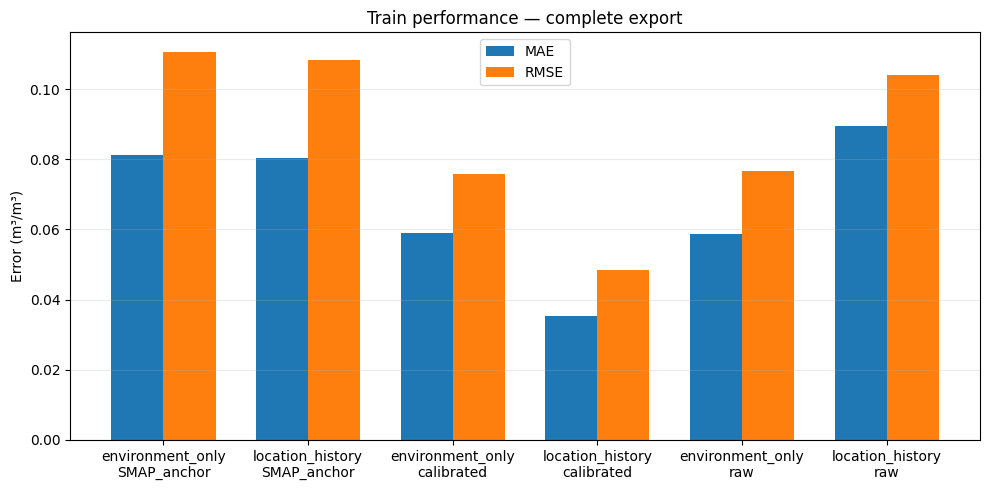

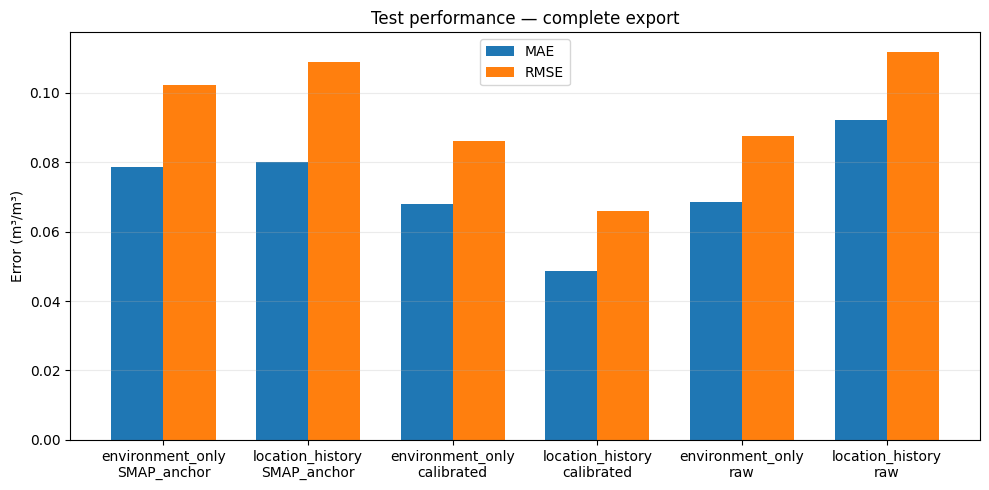

In [5]:
# 5. Metric calculations from complete Parquet scans

def metric_sql(view: str, pred_col: str, residual_col: str):
    return f"""
    SELECT
      COUNT(*)::BIGINT AS n,
      AVG({residual_col}) AS bias_m3_m3,
      AVG(ABS({residual_col})) AS mae_m3_m3,
      SQRT(AVG({residual_col} * {residual_col})) AS rmse_m3_m3,
      SQRT(GREATEST(AVG({residual_col} * {residual_col}) - POWER(AVG({residual_col}), 2), 0)) AS ubrmse_m3_m3,
      CASE WHEN (SUM(y_true_m3_m3*y_true_m3_m3) - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*)) > 0
           THEN 1.0 - SUM(POWER({residual_col}, 2)) /
                (SUM(y_true_m3_m3*y_true_m3_m3) - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*))
           ELSE NULL END AS r2,
      CORR(y_true_m3_m3, {pred_col}) AS pearson_r,
      AVG(y_true_m3_m3) AS mean_observed,
      AVG({pred_col}) AS mean_predicted
    FROM {view}
    WHERE y_true_m3_m3 IS NOT NULL AND {pred_col} IS NOT NULL
      AND isfinite(y_true_m3_m3) AND isfinite({pred_col}) AND isfinite({residual_col})
    """

metric_rows = []
for (mode, split), view in VIEWS.items():
    variants = [
        ("calibrated", "prediction_m3_m3", "residual_m3_m3"),
        ("raw", "raw_prediction_m3_m3", "raw_residual_m3_m3"),
    ]
    for variant, pred_col, resid_col in variants:
        result = DB.execute(metric_sql(view, pred_col, resid_col)).df().iloc[0].to_dict()
        result.update(task_mode=mode, split=split, variant=variant)
        metric_rows.append(result)
    anchor_result = DB.execute(f"""
        SELECT COUNT(*)::BIGINT AS n,
               AVG(anchor_smap_m3_m3 - y_true_m3_m3) AS bias_m3_m3,
               AVG(ABS(anchor_smap_m3_m3 - y_true_m3_m3)) AS mae_m3_m3,
               SQRT(AVG(POWER(anchor_smap_m3_m3 - y_true_m3_m3, 2))) AS rmse_m3_m3,
               CASE WHEN VAR_POP(y_true_m3_m3) > 0
                    THEN 1.0 - SUM(POWER(anchor_smap_m3_m3 - y_true_m3_m3, 2)) /
                         (SUM(y_true_m3_m3*y_true_m3_m3) - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*))
                    ELSE NULL END AS r2,
               CORR(y_true_m3_m3, anchor_smap_m3_m3) AS pearson_r,
               AVG(y_true_m3_m3) AS mean_observed,
               AVG(anchor_smap_m3_m3) AS mean_predicted
        FROM {view}
        WHERE anchor_smap_m3_m3 IS NOT NULL AND isfinite(anchor_smap_m3_m3)
          AND y_true_m3_m3 IS NOT NULL AND isfinite(y_true_m3_m3)
    """).df().iloc[0].to_dict()
    anchor_result["ubrmse_m3_m3"] = np.nan
    anchor_result.update(task_mode=mode, split=split, variant="SMAP_anchor")
    metric_rows.append(anchor_result)

METRICS = pd.DataFrame(metric_rows)[[
    "task_mode", "split", "variant", "n", "mae_m3_m3", "rmse_m3_m3",
    "ubrmse_m3_m3", "bias_m3_m3", "r2", "pearson_r", "mean_observed", "mean_predicted"
]]
METRICS = METRICS.sort_values(["split", "variant", "task_mode"]).reset_index(drop=True)
display(METRICS.round(5))
METRICS.to_csv(TABLES_DIR / "overall_metrics.csv", index=False)

# Plot summary metrics; all metrics above were calculated over the full exports.
for split in ("train", "test"):
    plot_df = METRICS[(METRICS.split == split) & METRICS.variant.isin(["calibrated", "raw", "SMAP_anchor"])]
    fig, ax = plt.subplots(figsize=(10, 5))
    labels = [f"{r.task_mode}\n{r.variant}" for r in plot_df.itertuples()]
    x = np.arange(len(plot_df))
    ax.bar(x - 0.18, plot_df["mae_m3_m3"], width=0.36, label="MAE")
    ax.bar(x + 0.18, plot_df["rmse_m3_m3"], width=0.36, label="RMSE")
    ax.set_xticks(x, labels)
    ax.set_ylabel("Error (m³/m³)")
    ax.set_title(f"{split.title()} performance — complete export")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"overall_{split}_mae_rmse.png", dpi=160)
    plt.show()
    plt.close(fig)

## 3) Apples-to-apples comparison on shared observations

The two task modes can have different eligible rows because their input requirements differ. Comparing their full-split scores alone may therefore mix model differences with sample-composition differences.

The paired analysis joins predictions by `network + station_id + sample_date + sample_id` within each split. It reports how many observations overlap, verifies the two target values agree, and compares errors only on the shared observations. A negative `location_minus_environment_mae` or `location_minus_environment_rmse` means the location-history model is better.

,split,location_rows,environment_rows,matched_rows,matched_pct_of_location,matched_pct_of_environment,max_abs_target_difference,mean_abs_target_difference
0,train,2216784,2544038,1768579,79.781296,69.518576,0.0,0.0
1,test,905248,644716,182528,20.163314,28.311381,0.0,0.0


,n,location_mae,location_rmse,location_bias,environment_mae,environment_rmse,environment_bias,location_r2,environment_r2,location_pearson_r,environment_pearson_r,location_minus_environment_mae,mean_squared_error_difference,location_win_pct,tie_pct,split
0,1768579.0,0.035098,0.047884,-0.000108,0.059335,0.076509,0.003983,0.832656,0.572779,0.912649,0.759266,-0.024237,-0.003561,70.111881,0.0,train
1,182528.0,0.049328,0.067041,-0.000638,0.066636,0.084902,0.005556,0.662614,0.458889,0.816187,0.679124,-0.017307,-0.002714,62.617242,0.0,test


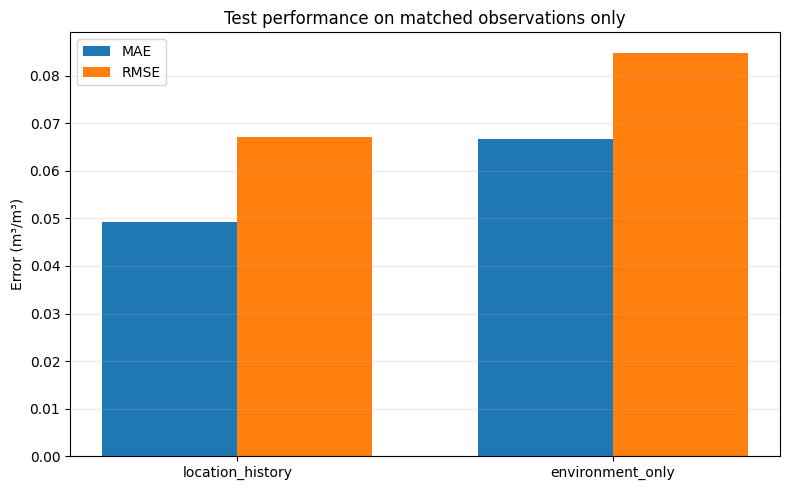

In [6]:
# 6. Build paired views, row overlap diagnostics, and matched-sample metrics
PAIR_KEYS = ["network", "station_id", "sample_date", "sample_id"]
PAIR_VIEWS = {}
pair_overlap_rows = []
paired_metric_rows = []

for split in ("train", "test"):
    lh = VIEWS[("location_history", split)]
    eo = VIEWS[("environment_only", split)]
    pview = f"paired_{split}"
    on_clause = " AND ".join([
        f"CAST(l.{k} AS VARCHAR) = CAST(e.{k} AS VARCHAR)" if k != "sample_date"
        else f"CAST(l.{k} AS DATE) = CAST(e.{k} AS DATE)"
        for k in PAIR_KEYS
    ])
    DB.execute(f"""
      CREATE OR REPLACE VIEW {pview} AS
      SELECT l.network, l.station_id, l.station_key AS location_station_key,
             l.sample_id, CAST(l.sample_date AS DATE) AS sample_date,
             l.latitude, l.longitude,
             l.y_true_m3_m3 AS y_location,
             e.y_true_m3_m3 AS y_environment,
             l.prediction_m3_m3 AS pred_location,
             e.prediction_m3_m3 AS pred_environment,
             l.residual_m3_m3 AS residual_location,
             e.residual_m3_m3 AS residual_environment,
             l.absolute_error_m3_m3 AS abs_error_location,
             e.absolute_error_m3_m3 AS abs_error_environment,
             l.raw_prediction_m3_m3 AS raw_pred_location,
             e.raw_prediction_m3_m3 AS raw_pred_environment,
             l.anchor_smap_m3_m3 AS anchor_location
      FROM {lh} l INNER JOIN {eo} e ON {on_clause}
    """)
    PAIR_VIEWS[split] = pview
    n_lh = DB.execute(f"SELECT COUNT(*) FROM {lh}").fetchone()[0]
    n_eo = DB.execute(f"SELECT COUNT(*) FROM {eo}").fetchone()[0]
    n_pair, target_max_diff, target_mean_diff = DB.execute(f"""
      SELECT COUNT(*), MAX(ABS(y_location-y_environment)), AVG(ABS(y_location-y_environment))
      FROM {pview}
    """).fetchone()
    pair_overlap_rows.append({"split": split, "location_rows": n_lh, "environment_rows": n_eo,
                              "matched_rows": n_pair,
                              "matched_pct_of_location": 100*n_pair/n_lh if n_lh else np.nan,
                              "matched_pct_of_environment": 100*n_pair/n_eo if n_eo else np.nan,
                              "max_abs_target_difference": target_max_diff,
                              "mean_abs_target_difference": target_mean_diff})
    paired = DB.execute(f"""
      SELECT COUNT(*)::BIGINT AS n,
        AVG(abs_error_location) AS location_mae,
        SQRT(AVG(POWER(residual_location,2))) AS location_rmse,
        AVG(residual_location) AS location_bias,
        AVG(abs_error_environment) AS environment_mae,
        SQRT(AVG(POWER(residual_environment,2))) AS environment_rmse,
        AVG(residual_environment) AS environment_bias,
        CASE WHEN (SUM(y_location*y_location)-SUM(y_location)*SUM(y_location)/COUNT(*)) > 0
             THEN 1.0-SUM(POWER(residual_location,2))/(SUM(y_location*y_location)-SUM(y_location)*SUM(y_location)/COUNT(*))
             ELSE NULL END AS location_r2,
        CASE WHEN (SUM(y_environment*y_environment)-SUM(y_environment)*SUM(y_environment)/COUNT(*)) > 0
             THEN 1.0-SUM(POWER(residual_environment,2))/(SUM(y_environment*y_environment)-SUM(y_environment)*SUM(y_environment)/COUNT(*))
             ELSE NULL END AS environment_r2,
        CORR(y_location, pred_location) AS location_pearson_r,
        CORR(y_environment, pred_environment) AS environment_pearson_r,
        AVG(abs_error_location-abs_error_environment) AS location_minus_environment_mae,
        AVG(POWER(residual_location,2)-POWER(residual_environment,2)) AS mean_squared_error_difference,
        100.0*AVG(CASE WHEN abs_error_location < abs_error_environment THEN 1.0 ELSE 0.0 END) AS location_win_pct,
        100.0*AVG(CASE WHEN abs_error_location = abs_error_environment THEN 1.0 ELSE 0.0 END) AS tie_pct
      FROM {pview}
      WHERE y_location IS NOT NULL AND y_environment IS NOT NULL
        AND ABS(y_location-y_environment) <= 1e-5
    """).df().iloc[0].to_dict()
    paired.update(split=split)
    paired_metric_rows.append(paired)

PAIR_OVERLAP = pd.DataFrame(pair_overlap_rows)
PAIRED_METRICS = pd.DataFrame(paired_metric_rows)
display(PAIR_OVERLAP.round(6))
display(PAIRED_METRICS.round(6))
PAIR_OVERLAP.to_csv(TABLES_DIR / "paired_overlap.csv", index=False)
PAIRED_METRICS.to_csv(TABLES_DIR / "paired_metrics.csv", index=False)

if (PAIR_OVERLAP["max_abs_target_difference"].fillna(0) > 1e-5).any():
    warnings.warn("Matched rows contain differing target values. Investigate before interpreting paired score differences.")

# Test split: compare the two models on exactly the same rows.
fig, ax = plt.subplots(figsize=(8, 5))
plot_pair = PAIRED_METRICS[PAIRED_METRICS.split == "test"].iloc[0]
bar_labels = ["location_history", "environment_only"]
mae_vals = [plot_pair.location_mae, plot_pair.environment_mae]
rmse_vals = [plot_pair.location_rmse, plot_pair.environment_rmse]
x = np.arange(2)
ax.bar(x - 0.18, mae_vals, width=0.36, label="MAE")
ax.bar(x + 0.18, rmse_vals, width=0.36, label="RMSE")
ax.set_xticks(x, bar_labels)
ax.set_ylabel("Error (m³/m³)")
ax.set_title("Test performance on matched observations only")
ax.legend(); ax.grid(axis="y", alpha=0.25)
fig.tight_layout(); fig.savefig(PLOTS_DIR / "paired_test_metrics.png", dpi=160); plt.show(); plt.close(fig)

## 4) Prediction and residual diagnostics

These plots use a deterministic sample for display only; the summary metrics and grouped analyses continue to use the complete prediction Parquet files. Look for systematic under-/overprediction, compression toward the mean, heteroscedasticity (error growing with moisture), and outliers.

location_history train plot sample: 60,000
environment_only train plot sample: 60,000
location_history test plot sample: 60,000
environment_only test plot sample: 60,000


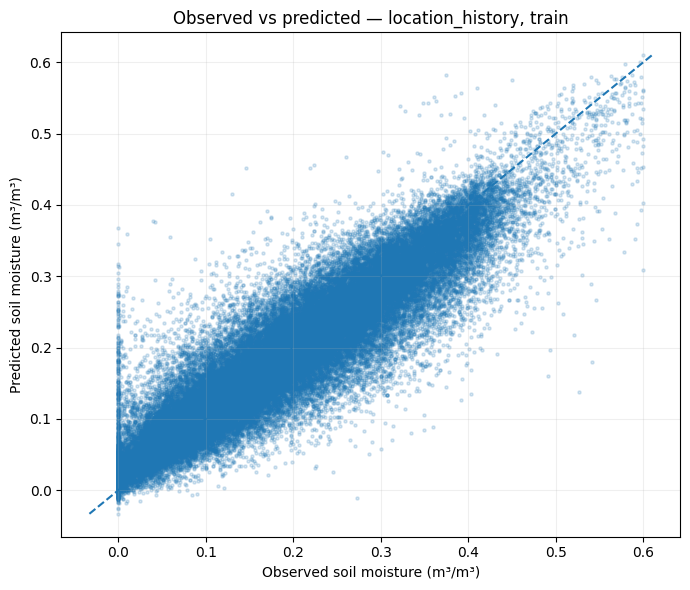

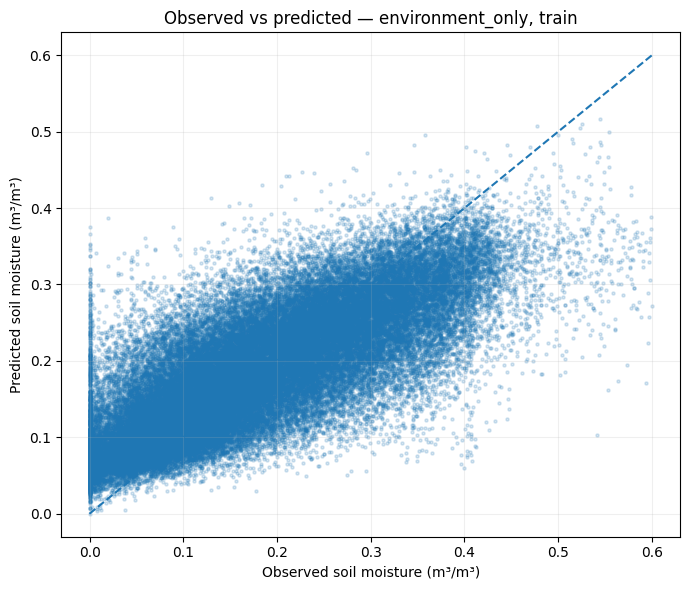

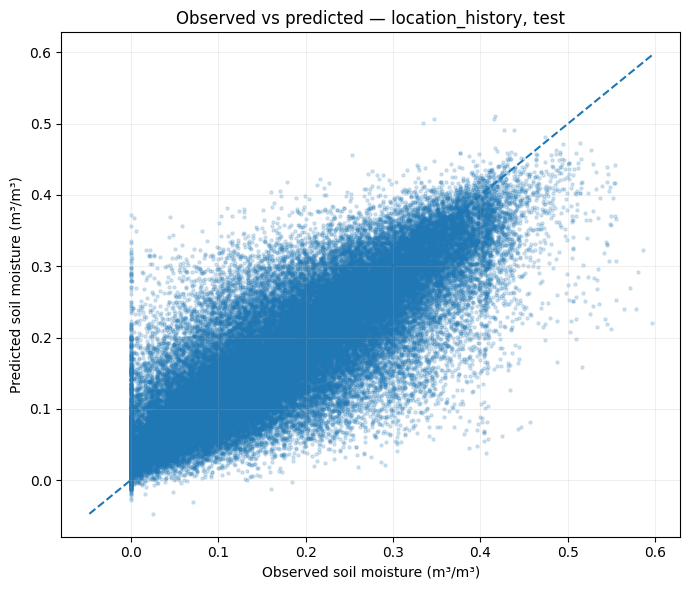

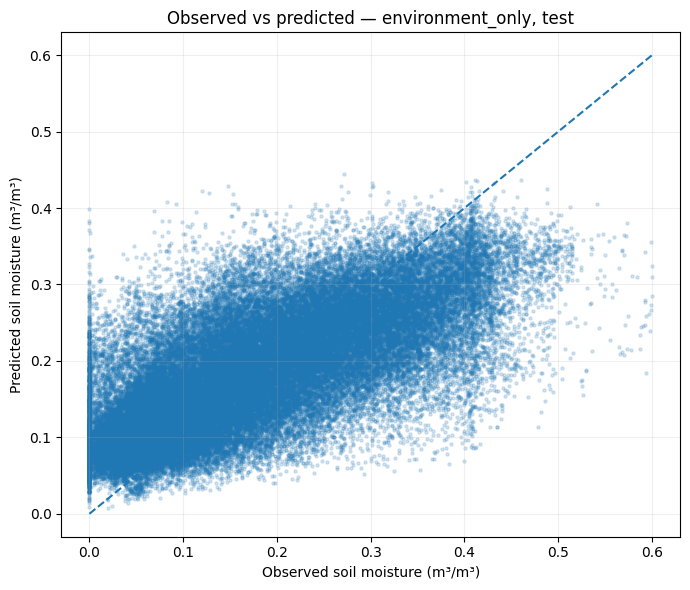

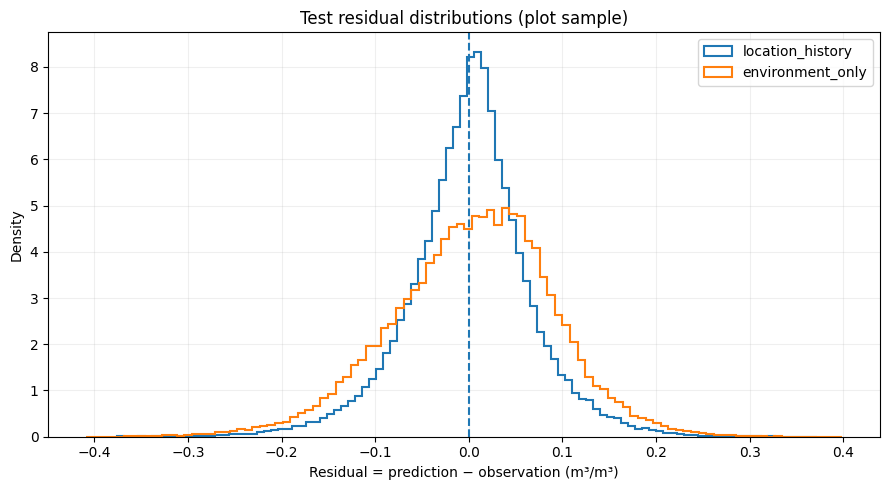

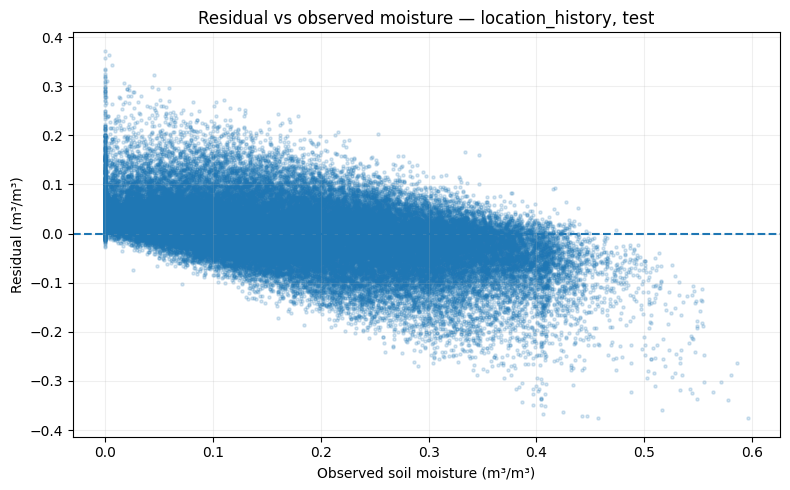

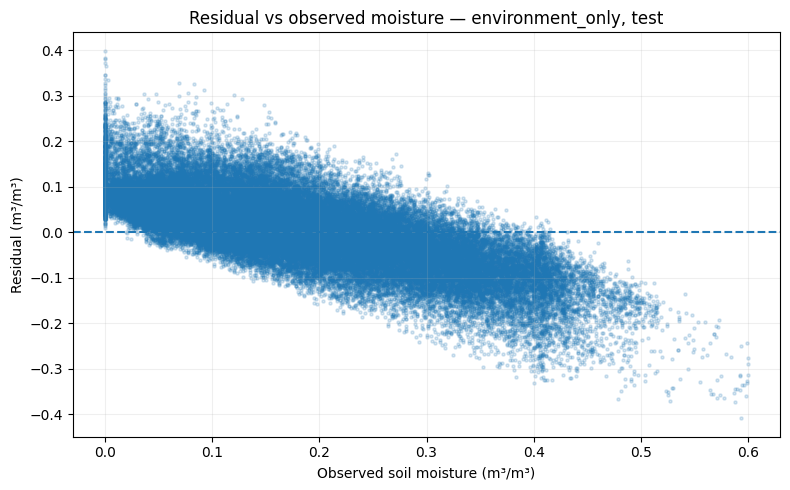

In [7]:
# 7. Pull a bounded plotting sample and inspect observed-vs-predicted values

def fetch_plot_sample(view, n=PLOT_SAMPLE_PER_SPLIT):
    return DB.execute(f"""
      SELECT sample_id, network, station_id, CAST(sample_date AS DATE) AS sample_date,
             latitude, longitude, y_true_m3_m3,
             prediction_m3_m3, raw_prediction_m3_m3,
             residual_m3_m3, absolute_error_m3_m3,
             anchor_smap_m3_m3
      FROM {view}
      WHERE isfinite(y_true_m3_m3) AND isfinite(prediction_m3_m3)
      ORDER BY hash(CAST(sample_id AS VARCHAR))
      LIMIT {int(n)}
    """).df()

PLOT_SAMPLES = {}
for split in ("train", "test"):
    for mode in ("location_history", "environment_only"):
        df = fetch_plot_sample(VIEWS[(mode, split)])
        PLOT_SAMPLES[(mode, split)] = df
        print(mode, split, "plot sample:", f"{len(df):,}")

for split in ("train", "test"):
    for mode in ("location_history", "environment_only"):
        df = PLOT_SAMPLES[(mode, split)]
        fig, ax = plt.subplots(figsize=(7, 6))
        ax.scatter(df.y_true_m3_m3, df.prediction_m3_m3, s=5, alpha=0.18)
        lo = np.nanmin([df.y_true_m3_m3.min(), df.prediction_m3_m3.min()])
        hi = np.nanmax([df.y_true_m3_m3.max(), df.prediction_m3_m3.max()])
        ax.plot([lo, hi], [lo, hi], linestyle="--")
        ax.set_xlabel("Observed soil moisture (m³/m³)")
        ax.set_ylabel("Predicted soil moisture (m³/m³)")
        ax.set_title(f"Observed vs predicted — {mode}, {split}")
        ax.grid(alpha=0.2); fig.tight_layout()
        fig.savefig(PLOTS_DIR / f"observed_vs_predicted_{mode}_{split}.png", dpi=160)
        plt.show(); plt.close(fig)

# Residual distributions and residual-vs-target diagnostics for both models on test.
fig, ax = plt.subplots(figsize=(9, 5))
for mode in ("location_history", "environment_only"):
    df = PLOT_SAMPLES[(mode, "test")]
    ax.hist(df.residual_m3_m3.dropna(), bins=100, density=True, histtype="step", linewidth=1.5, label=mode)
ax.axvline(0, linestyle="--")
ax.set_xlabel("Residual = prediction − observation (m³/m³)")
ax.set_ylabel("Density")
ax.set_title("Test residual distributions (plot sample)")
ax.legend(); ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig(PLOTS_DIR / "test_residual_distributions.png", dpi=160); plt.show(); plt.close(fig)

for mode in ("location_history", "environment_only"):
    df = PLOT_SAMPLES[(mode, "test")]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(df.y_true_m3_m3, df.residual_m3_m3, s=5, alpha=0.18)
    ax.axhline(0, linestyle="--")
    ax.set_xlabel("Observed soil moisture (m³/m³)")
    ax.set_ylabel("Residual (m³/m³)")
    ax.set_title(f"Residual vs observed moisture — {mode}, test")
    ax.grid(alpha=0.2); fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"residual_vs_target_{mode}_test.png", dpi=160)
    plt.show(); plt.close(fig)

## 5) Station-level and network-level error patterns

Station metrics use every prediction for that station. Small stations can have unstable metrics, so the default table/plots filter to stations with at least `MIN_STATION_ROWS` observations. The full unfiltered summary is still saved as CSV.

,network,station_id,n,latitude,longitude,bias_m3_m3,mae_m3_m3,rmse_m3_m3,r2
2344,SNOTEL,SNOTEL__MF_Nooksack,191,48.82441,-121.92947,0.25124,0.25124,0.26078,NaN
2876,FMI,FMI__SOD021,58,67.36691,26.65176,-0.21528,0.21528,0.22969,-10.52379
2852,USCRN,USCRN__Coos_Bay_8_SW,422,43.27180,-124.31860,-0.19146,0.19590,0.22508,-3.40769
3062,FMI,FMI__SOD101,556,67.35919,26.68595,-0.19215,0.19250,0.20625,-6.11293
2101,SCAN,SCAN__Guilarte_Forest,621,18.14638,-66.76718,-0.17737,0.17949,0.19889,-3.12894
2612,SNOTEL,SNOTEL__Kelly_Station,258,67.92970,-162.29060,-0.11632,0.16211,0.19345,-0.73079
2287,SNOTEL,SNOTEL__Poison_Flat,546,38.50576,-119.62624,-0.15031,0.15433,0.18028,-1.28990
2319,SNOTEL,SNOTEL__Sheep_Mtn.,813,43.21030,-111.68792,0.10879,0.14728,0.17425,-0.74236
2554,SNOTEL,SNOTEL__Two_Ocean_Plateau,247,44.15178,-110.22122,-0.15171,0.15476,0.16985,-4.36029
2872,SNOTEL,SNOTEL__Middle_Fork_Camp,96,39.79565,-106.02802,-0.12212,0.14944,0.16734,-1.08231


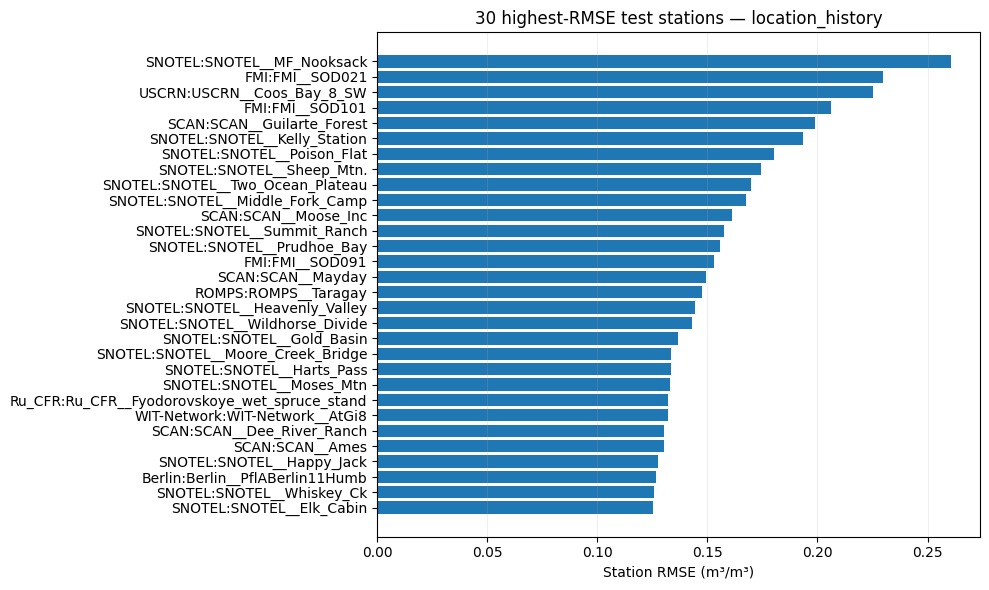

,network,station_id,n,latitude,longitude,bias_m3_m3,mae_m3_m3,rmse_m3_m3,r2
5089,BIEBRZA_S-1,BIEBRZA_S-1__marshland_soil_25,24,53.62030,22.87915,-0.30866,0.30866,0.31070,-1121.14333
5161,TWENTE,TWENTE__ITCSM_06a,81,52.41389,6.63667,-0.30028,0.30028,0.30447,-20.42972
5087,BIEBRZA_S-1,BIEBRZA_S-1__marshland_soil_28,41,53.62178,22.87884,-0.28903,0.28903,0.29627,-61.51851
4980,BIEBRZA_S-1,BIEBRZA_S-1__marshland_soil_23,64,53.61899,22.88195,-0.26665,0.26665,0.27451,-47.71373
5268,MySMNet,MySMNet__MPOB-BL1,275,1.91700,103.44800,0.27195,0.27195,0.27396,-56.43399
4968,FMI,FMI__SOD092,218,67.37074,26.63978,-0.25789,0.25789,0.26216,-33.27232
5276,BIEBRZA_S-1,BIEBRZA_S-1__marshland_soil_15,337,53.60578,22.87850,-0.20791,0.20840,0.22285,-11.53509
5156,COSMOS,COSMOS__Howland,572,45.20410,-68.74020,-0.21193,0.21193,0.21811,-12.81090
5173,SNOTEL,SNOTEL__Elwood_Pass,168,37.40563,-106.64136,-0.20698,0.20698,0.21270,-10.08906
5199,MySMNet,MySMNet__MARDI-L2,275,1.97400,103.35800,0.20682,0.20682,0.21126,-13.31565


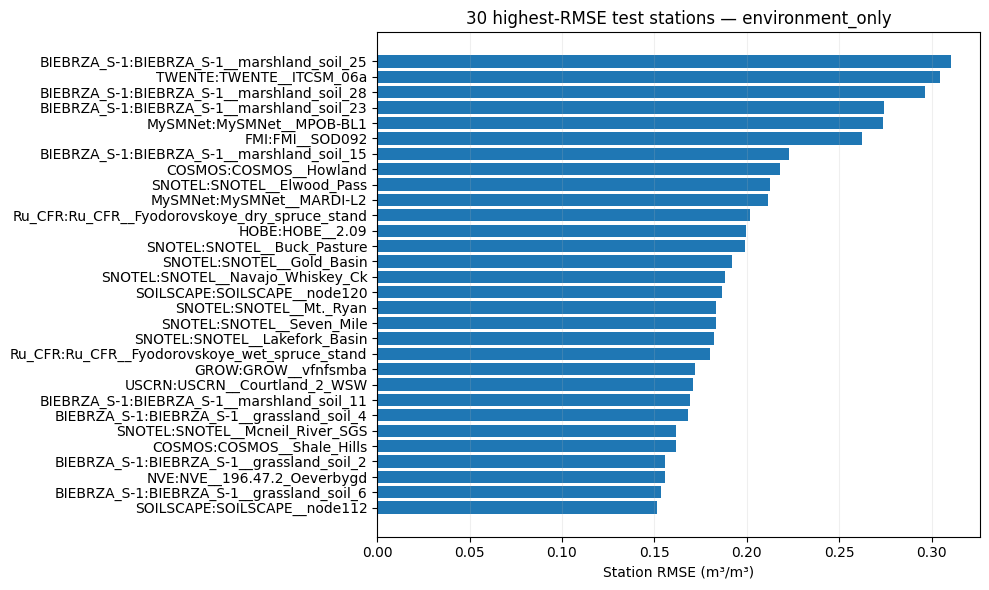

,task_mode,split,network,n,n_stations,bias_m3_m3,mae_m3_m3,rmse_m3_m3,pearson_r
148,environment_only,test,MySMNet,1042,4,0.18330,0.18330,0.19990,0.16313
152,environment_only,test,Ru_CFR,1487,2,-0.17223,0.18186,0.19806,0.08630
156,environment_only,test,BIEBRZA_S-1,3956,10,-0.15048,0.15059,0.17110,0.56065
185,environment_only,test,IPE,1027,1,0.13759,0.13759,0.14773,0.68517
175,environment_only,test,TWENTE,8518,7,-0.09256,0.10036,0.12476,0.71934
...,...,...,...,...,...,...,...,...,...
77,location_history,test,REMEDHUS,12741,18,-0.00765,0.02832,0.03981,0.91074
149,environment_only,test,IMA_CAN1,247,1,-0.00787,0.03043,0.03865,0.66069
146,environment_only,test,CTP_SMTMN,503,12,0.00593,0.03033,0.03574,0.35692
67,location_history,test,FR_Aqui,1623,3,0.00389,0.02659,0.03532,0.72759


In [8]:
# 8. Complete per-station metrics for each model and split
station_frames = []
for (mode, split), view in VIEWS.items():
    part = DB.execute(f"""
      SELECT '{mode}' AS task_mode, '{split}' AS split,
             network, station_id, station_key,
             AVG(latitude) AS latitude, AVG(longitude) AS longitude,
             COUNT(*)::BIGINT AS n,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3,
             CASE WHEN (SUM(y_true_m3_m3*y_true_m3_m3)
                        - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*)) > 0
                  THEN 1.0 - SUM(squared_error_m3_m6) /
                       (SUM(y_true_m3_m3*y_true_m3_m3)
                        - SUM(y_true_m3_m3)*SUM(y_true_m3_m3)/COUNT(*))
                  ELSE NULL END AS r2,
             CORR(y_true_m3_m3, prediction_m3_m3) AS pearson_r
      FROM {view}
      GROUP BY network, station_id, station_key
    """).df()
    station_frames.append(part)
STATION_METRICS = pd.concat(station_frames, ignore_index=True)
STATION_METRICS.to_csv(TABLES_DIR / "station_metrics_all.csv", index=False)

STATION_TEST = STATION_METRICS[(STATION_METRICS.split == "test") & (STATION_METRICS.n >= MIN_STATION_ROWS)].copy()
for mode in ("location_history", "environment_only"):
    worst = STATION_TEST[STATION_TEST.task_mode == mode].nlargest(30, "rmse_m3_m3")
    worst.to_csv(TABLES_DIR / f"worst_30_stations_{mode}_test.csv", index=False)
    display(worst[["network", "station_id", "n", "latitude", "longitude", "bias_m3_m3", "mae_m3_m3", "rmse_m3_m3", "r2"]].head(15).round(5))
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_worst = worst.sort_values("rmse_m3_m3", ascending=True)
    labels = (plot_worst.network.astype(str) + ":" + plot_worst.station_id.astype(str)).tolist()
    ax.barh(labels, plot_worst.rmse_m3_m3)
    ax.set_xlabel("Station RMSE (m³/m³)")
    ax.set_title(f"30 highest-RMSE test stations — {mode}")
    ax.grid(axis="x", alpha=0.2); fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"worst_30_stations_{mode}_test.png", dpi=160)
    plt.show(); plt.close(fig)

# Network summaries expose whether a few networks dominate the error.
network_frames = []
for (mode, split), view in VIEWS.items():
    part = DB.execute(f"""
      SELECT '{mode}' AS task_mode, '{split}' AS split, network,
             COUNT(*)::BIGINT AS n,
             COUNT(DISTINCT station_key) AS n_stations,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3,
             CORR(y_true_m3_m3, prediction_m3_m3) AS pearson_r
      FROM {view} GROUP BY network
    """).df()
    network_frames.append(part)
NETWORK_METRICS = pd.concat(network_frames, ignore_index=True)
NETWORK_METRICS.to_csv(TABLES_DIR / "network_metrics.csv", index=False)
display(NETWORK_METRICS[NETWORK_METRICS.split == "test"].sort_values("rmse_m3_m3", ascending=False).round(5))

## 6) Direct station-by-station model comparison

This isolates where location history helps or hurts, using only matched test observations and identical target values. `location_minus_environment_rmse < 0` means location history lowers station RMSE. The win-rate is the percentage of matched observations where the absolute error from `location_history` is smaller.

Stations where location_history lowers RMSE the most (test):


,split,network,station_id,n,location_mae,location_rmse,environment_mae,environment_rmse,location_minus_environment_mae,location_minus_environment_rmse,location_win_pct
1884,test,SNOTEL,SNOTEL__Mt._Ryan,585,0.08822,0.10166,0.20136,0.20549,-0.11314,-0.10383,100.00000
1713,test,Ru_CFR,Ru_CFR__Fyodorovskoye_dry_spruce_stand,419,0.09403,0.12050,0.21920,0.22350,-0.12517,-0.10300,93.07876
1851,test,REMEDHUS,REMEDHUS__El_Coto,574,0.03245,0.03624,0.12994,0.13752,-0.09750,-0.10128,99.82578
1830,test,RSMN,RSMN__Darabani,333,0.02660,0.03465,0.10865,0.12919,-0.08205,-0.09454,92.19219
1861,test,SNOTEL,SNOTEL__Navajo_Whiskey_Ck,1151,0.06855,0.08730,0.16774,0.18020,-0.09919,-0.09290,82.62381
1690,test,USCRN,USCRN__Watkinsville_5_SSE,1051,0.04271,0.05194,0.13965,0.14362,-0.09694,-0.09168,99.52426
1775,test,SNOTEL,SNOTEL__Buck_Pasture,727,0.07838,0.11102,0.19041,0.19886,-0.11203,-0.08785,81.98074
1719,test,USCRN,USCRN__John_Day_35_WNW,1201,0.03053,0.03889,0.11040,0.12231,-0.07987,-0.08342,97.91840
1846,test,SNOTEL,SNOTEL__Atlanta_Summit,596,0.05768,0.07472,0.14172,0.15516,-0.08405,-0.08044,94.63087
1688,test,SCAN,SCAN__Watkinsville_#1,1365,0.03799,0.04994,0.11828,0.12498,-0.08029,-0.07504,90.10989


Stations where environment_only lowers RMSE the most (test):


,split,network,station_id,n,location_mae,location_rmse,environment_mae,environment_rmse,location_minus_environment_mae,location_minus_environment_rmse,location_win_pct
1764,test,SCAN,SCAN__Johnson_Farm,1208,0.09126,0.10466,0.04728,0.05694,0.04399,0.04772,15.97682
1832,test,SNOTEL,SNOTEL__Middle_Fork_Camp,96,0.14944,0.16734,0.11137,0.13162,0.03806,0.03572,20.83333
1683,test,SNOTEL,SNOTEL__Elk_Cabin,1096,0.10122,0.12524,0.07531,0.09214,0.02590,0.03309,31.66058
1727,test,Berlin,Berlin__PflABerlin11Humb,1282,0.11733,0.12659,0.08393,0.09394,0.03339,0.03265,9.20437
1760,test,USCRN,USCRN__Edinburg_17_NNE,1324,0.05720,0.06493,0.02868,0.03364,0.02853,0.03129,15.25680
1785,test,SNOTEL,SNOTEL__Two_Ocean_Plateau,247,0.15476,0.16985,0.13663,0.14528,0.01813,0.02457,38.05668
1876,test,SNOTEL,SNOTEL__Bear_Creek,952,0.05257,0.06303,0.03093,0.03907,0.02164,0.02396,30.56723
1723,test,SNOTEL,SNOTEL__Chemult_Alternate,282,0.06924,0.08186,0.04540,0.05793,0.02385,0.02393,26.59574
1788,test,XMS-CAT,XMS-CAT__Clarella,1316,0.07864,0.09801,0.06293,0.07494,0.01571,0.02308,34.87842
1696,test,RISMA,RISMA__MB24,646,0.04124,0.05292,0.02738,0.03428,0.01386,0.01865,33.59133


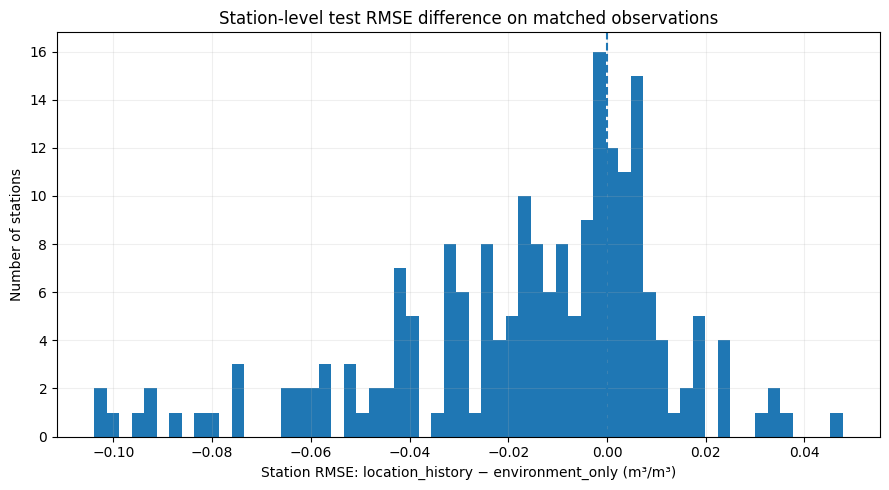

,network,n,location_mae,location_rmse,environment_mae,environment_rmse,location_minus_environment_mae,location_win_pct
15,Ru_CFR,517,0.09784,0.12283,0.20935,0.21727,-0.11151,89.36170
18,COSMOS-UK,5,0.03407,0.04078,0.10104,0.12006,-0.06696,100.00000
5,REMEDHUS,4212,0.02796,0.03602,0.06729,0.08041,-0.03933,79.39221
12,RSMN,1001,0.04632,0.05885,0.07762,0.09976,-0.03130,62.43756
2,USCRN,26083,0.03640,0.04843,0.06128,0.07559,-0.02488,69.68524
13,iRON,938,0.03654,0.04621,0.05703,0.07384,-0.02049,61.19403
16,ARM,480,0.03148,0.04012,0.05184,0.06240,-0.02037,69.79167
8,SMOSMANIA,3489,0.03761,0.04800,0.05724,0.07439,-0.01963,65.20493
7,Berlin,3768,0.06331,0.08236,0.08059,0.08973,-0.01727,58.41295
0,SNOTEL,74774,0.06162,0.08057,0.07836,0.09850,-0.01674,60.87276


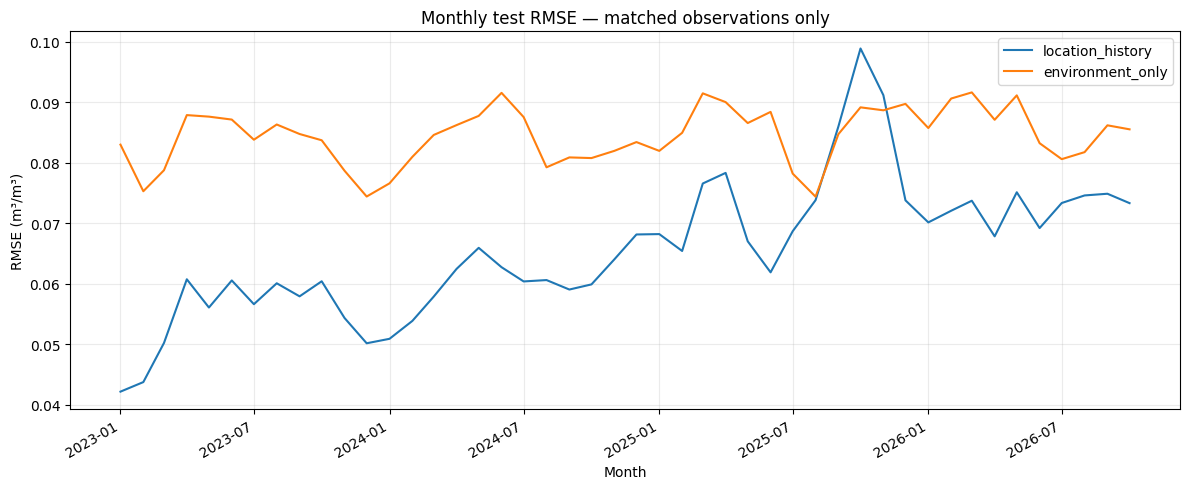

In [9]:
# 9. Per-station paired comparison on shared test samples
paired_station_parts = []
for split, pview in PAIR_VIEWS.items():
    part = DB.execute(f"""
      SELECT '{split}' AS split, network, station_id,
             COUNT(*)::BIGINT AS n,
             AVG(abs_error_location) AS location_mae,
             SQRT(AVG(POWER(residual_location, 2))) AS location_rmse,
             AVG(abs_error_environment) AS environment_mae,
             SQRT(AVG(POWER(residual_environment, 2))) AS environment_rmse,
             AVG(abs_error_location-abs_error_environment) AS location_minus_environment_mae,
             SQRT(AVG(POWER(residual_location,2))) - SQRT(AVG(POWER(residual_environment,2))) AS location_minus_environment_rmse,
             100.0*AVG(CASE WHEN abs_error_location < abs_error_environment THEN 1.0 ELSE 0.0 END) AS location_win_pct
      FROM {pview}
      WHERE ABS(y_location-y_environment) <= 1e-5
      GROUP BY network, station_id
    """).df()
    paired_station_parts.append(part)
PAIRED_STATION = pd.concat(paired_station_parts, ignore_index=True)
PAIRED_STATION.to_csv(TABLES_DIR / "paired_station_comparison.csv", index=False)
PAIRED_TEST_STATION = PAIRED_STATION[(PAIRED_STATION.split == "test") & (PAIRED_STATION.n >= MIN_STATION_ROWS)].copy()

print("Stations where location_history lowers RMSE the most (test):")
display(PAIRED_TEST_STATION.nsmallest(20, "location_minus_environment_rmse").round(5))
print("Stations where environment_only lowers RMSE the most (test):")
display(PAIRED_TEST_STATION.nlargest(20, "location_minus_environment_rmse").round(5))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(PAIRED_TEST_STATION.location_minus_environment_rmse.dropna(), bins=60)
ax.axvline(0, linestyle="--")
ax.set_xlabel("Station RMSE: location_history − environment_only (m³/m³)")
ax.set_ylabel("Number of stations")
ax.set_title("Station-level test RMSE difference on matched observations")
ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig(PLOTS_DIR / "paired_station_rmse_difference_test.png", dpi=160)
plt.show(); plt.close(fig)

# Network-level paired comparison.
paired_network = DB.execute(f"""
  SELECT network, COUNT(*)::BIGINT AS n,
         AVG(abs_error_location) AS location_mae,
         SQRT(AVG(POWER(residual_location,2))) AS location_rmse,
         AVG(abs_error_environment) AS environment_mae,
         SQRT(AVG(POWER(residual_environment,2))) AS environment_rmse,
         AVG(abs_error_location-abs_error_environment) AS location_minus_environment_mae,
         100.0*AVG(CASE WHEN abs_error_location < abs_error_environment THEN 1.0 ELSE 0.0 END) AS location_win_pct
  FROM {PAIR_VIEWS['test']}
  WHERE ABS(y_location-y_environment) <= 1e-5
  GROUP BY network ORDER BY n DESC
""").df()
paired_network.to_csv(TABLES_DIR / "paired_network_comparison_test.csv", index=False)
display(paired_network.sort_values("location_minus_environment_mae").round(5))

# Monthly paired comparison: both models scored on the same test rows each month.
PAIRED_MONTHLY_TEST = DB.execute(f"""
  SELECT DATE_TRUNC('month', sample_date) AS month,
         COUNT(*)::BIGINT AS n,
         AVG(abs_error_location) AS location_mae,
         SQRT(AVG(POWER(residual_location,2))) AS location_rmse,
         AVG(abs_error_environment) AS environment_mae,
         SQRT(AVG(POWER(residual_environment,2))) AS environment_rmse,
         AVG(abs_error_location-abs_error_environment) AS location_minus_environment_mae,
         100.0*AVG(CASE WHEN abs_error_location < abs_error_environment THEN 1.0 ELSE 0.0 END) AS location_win_pct
  FROM {PAIR_VIEWS['test']}
  WHERE ABS(y_location-y_environment) <= 1e-5
  GROUP BY month ORDER BY month
""").df()
PAIRED_MONTHLY_TEST.to_csv(TABLES_DIR / "paired_monthly_comparison_test.csv", index=False)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pd.to_datetime(PAIRED_MONTHLY_TEST.month), PAIRED_MONTHLY_TEST.location_rmse, label="location_history")
ax.plot(pd.to_datetime(PAIRED_MONTHLY_TEST.month), PAIRED_MONTHLY_TEST.environment_rmse, label="environment_only")
ax.set_xlabel("Month"); ax.set_ylabel("RMSE (m³/m³)")
ax.set_title("Monthly test RMSE — matched observations only")
ax.legend(); ax.grid(alpha=0.25); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(PLOTS_DIR / "paired_monthly_test_rmse.png", dpi=160)
plt.show(); plt.close(fig)


## 7) Geographic error patterns

The export includes station latitude and longitude. The plots below are longitude/latitude scatter views, not political-boundary maps. A grid summary uses 2° cells by default, reducing station-level noise while preserving broad geographic structure.

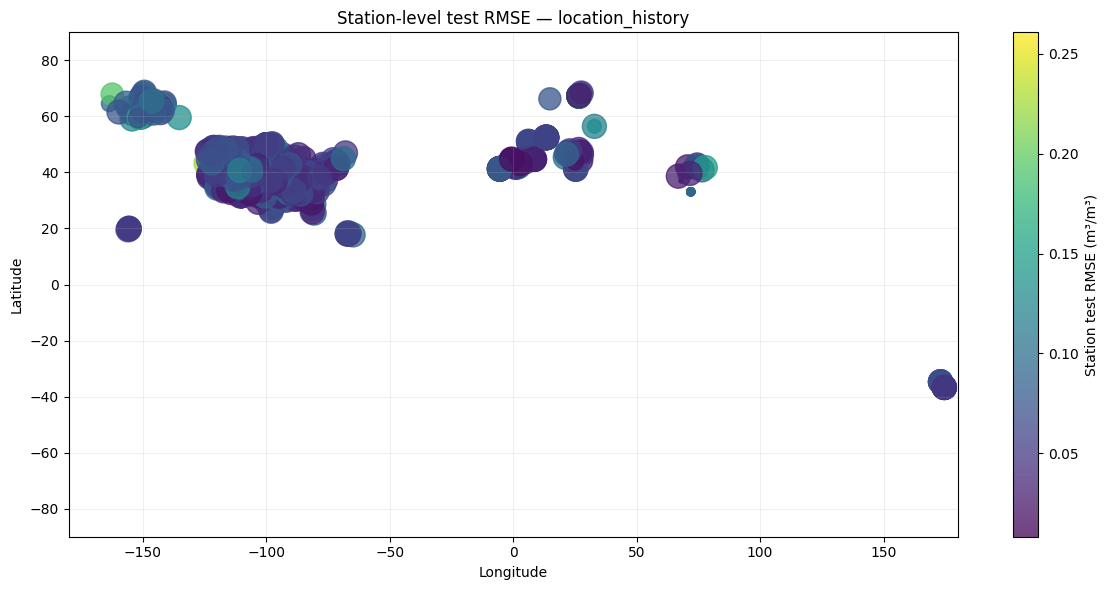

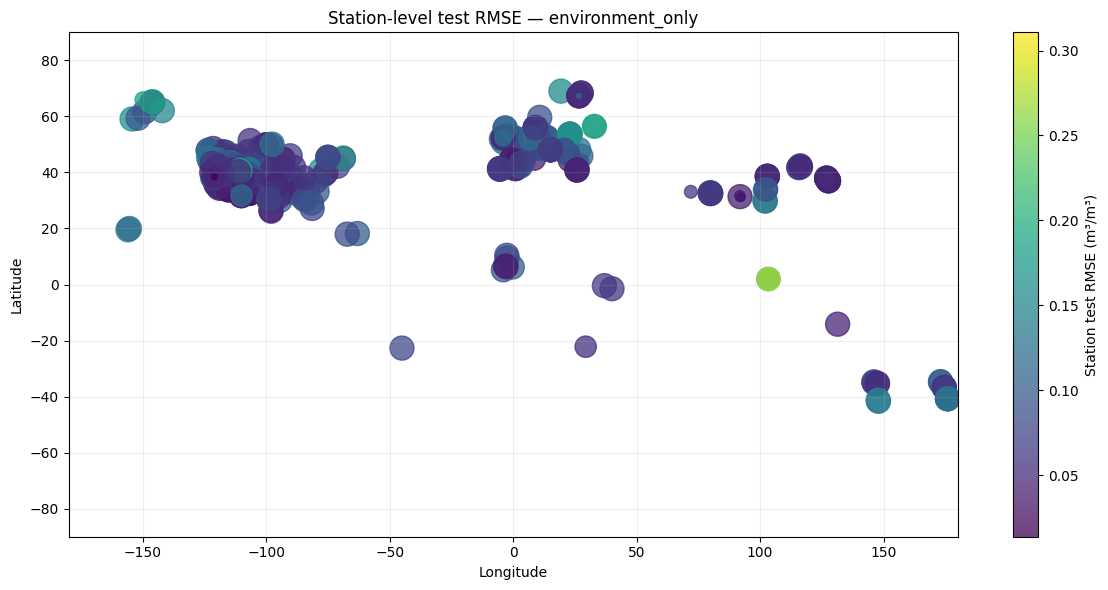

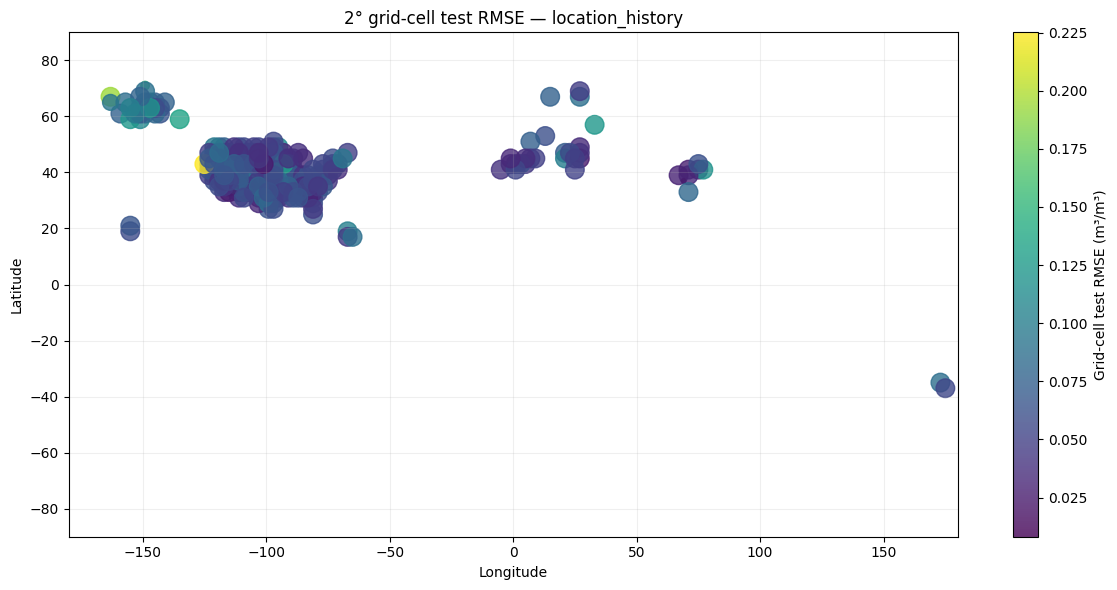

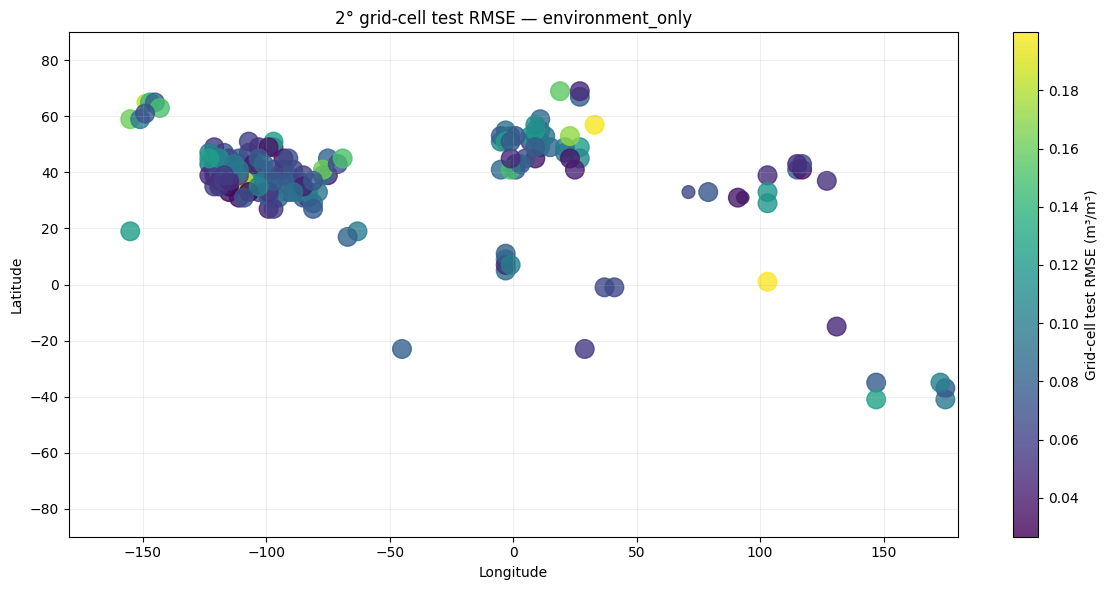

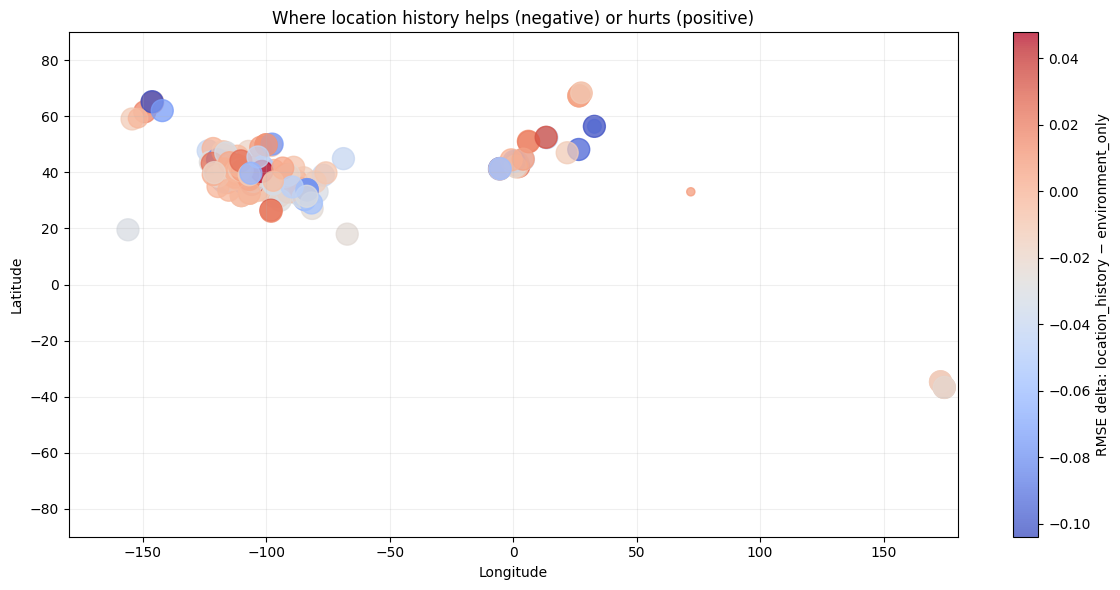

In [10]:
# 10. Station maps and grid-cell error summaries for test
for mode in ("location_history", "environment_only"):
    st = STATION_TEST[STATION_TEST.task_mode == mode].dropna(subset=["latitude", "longitude", "rmse_m3_m3"])
    fig, ax = plt.subplots(figsize=(12, 6))
    sc = ax.scatter(st.longitude, st.latitude, c=st.rmse_m3_m3, s=np.clip(st.n, 10, 300),
                    alpha=0.75)
    fig.colorbar(sc, ax=ax, label="Station test RMSE (m³/m³)")
    ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_title(f"Station-level test RMSE — {mode}")
    ax.grid(alpha=0.2); fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"station_error_map_{mode}_test.png", dpi=160)
    plt.show(); plt.close(fig)

spatial_parts = []
for mode, view in [("location_history", VIEWS[("location_history", "test")]),
                   ("environment_only", VIEWS[("environment_only", "test")])]:
    deg = float(SPATIAL_GRID_DEGREES)
    part = DB.execute(f"""
      SELECT '{mode}' AS task_mode,
        FLOOR((latitude + 90.0) / {deg}) * {deg} - 90.0 AS lat_bin,
        FLOOR((longitude + 180.0) / {deg}) * {deg} - 180.0 AS lon_bin,
        COUNT(*)::BIGINT AS n,
        AVG(residual_m3_m3) AS bias_m3_m3,
        AVG(absolute_error_m3_m3) AS mae_m3_m3,
        SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
      FROM {view}
      WHERE latitude BETWEEN -90 AND 90 AND longitude BETWEEN -180 AND 180
      GROUP BY lat_bin, lon_bin HAVING COUNT(*) >= {MIN_STATION_ROWS}
    """).df()
    spatial_parts.append(part)
SPATIAL_METRICS = pd.concat(spatial_parts, ignore_index=True)
SPATIAL_METRICS.to_csv(TABLES_DIR / "spatial_grid_metrics_test.csv", index=False)

for mode in ("location_history", "environment_only"):
    grid = SPATIAL_METRICS[SPATIAL_METRICS.task_mode == mode]
    fig, ax = plt.subplots(figsize=(12, 6))
    sc = ax.scatter(grid.lon_bin + SPATIAL_GRID_DEGREES/2,
                    grid.lat_bin + SPATIAL_GRID_DEGREES/2,
                    c=grid.rmse_m3_m3, s=np.clip(grid.n, 5, 180), alpha=0.8)
    fig.colorbar(sc, ax=ax, label="Grid-cell test RMSE (m³/m³)")
    ax.set_xlim(-180,180); ax.set_ylim(-90,90)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_title(f"{SPATIAL_GRID_DEGREES:g}° grid-cell test RMSE — {mode}")
    ax.grid(alpha=0.2); fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"spatial_grid_error_{mode}_test.png", dpi=160)
    plt.show(); plt.close(fig)

# Paired station delta map: the sign is especially useful for locating where history helps.
coords = DB.execute(f"""
  SELECT network, station_id, AVG(latitude) latitude, AVG(longitude) longitude,
         COUNT(*) n,
         SQRT(AVG(POWER(residual_location,2))) - SQRT(AVG(POWER(residual_environment,2))) AS rmse_delta
  FROM {PAIR_VIEWS['test']}
  WHERE ABS(y_location-y_environment) <= 1e-5
  GROUP BY network, station_id HAVING COUNT(*) >= {MIN_STATION_ROWS}
""").df()
coords.to_csv(TABLES_DIR / "paired_station_rmse_delta_map_data.csv", index=False)
fig, ax = plt.subplots(figsize=(12, 6))
sc = ax.scatter(coords.longitude, coords.latitude, c=coords.rmse_delta,
                s=np.clip(coords.n, 10, 250), alpha=0.75, cmap="coolwarm")
fig.colorbar(sc, ax=ax, label="RMSE delta: location_history − environment_only")
ax.set_xlim(-180,180); ax.set_ylim(-90,90)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Where location history helps (negative) or hurts (positive)")
ax.grid(alpha=0.2); fig.tight_layout()
fig.savefig(PLOTS_DIR / "paired_station_rmse_delta_map_test.png", dpi=160)
plt.show(); plt.close(fig)

## 8) Time, seasonality, and moisture-regime diagnostics

These summaries can reveal whether the models struggle in particular years, months, or soil-moisture regimes. Monthly/yearly summaries are computed over the complete exports; the target-bin plots likewise use all rows.

In [11]:
# 11. Annual and monthly test error trends
annual_parts, monthly_parts, target_bin_parts, season_parts = [], [], [], []
for mode, view in [("location_history", VIEWS[("location_history", "test")]),
                   ("environment_only", VIEWS[("environment_only", "test")])]:
    annual = DB.execute(f"""
      SELECT '{mode}' AS task_mode, YEAR(CAST(sample_date AS DATE)) AS year,
             COUNT(*)::BIGINT AS n, AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
      FROM {view} GROUP BY year ORDER BY year
    """).df()
    monthly = DB.execute(f"""
      SELECT '{mode}' AS task_mode, DATE_TRUNC('month', CAST(sample_date AS DATE)) AS month,
             COUNT(*)::BIGINT AS n, AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
      FROM {view} GROUP BY month ORDER BY month
    """).df()
    season = DB.execute(f"""
      SELECT '{mode}' AS task_mode, MONTH(CAST(sample_date AS DATE)) AS month_of_year,
             COUNT(*)::BIGINT AS n, AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
      FROM {view} GROUP BY month_of_year ORDER BY month_of_year
    """).df()
    bins = DB.execute(f"""
      SELECT '{mode}' AS task_mode,
             FLOOR(y_true_m3_m3 / 0.05) * 0.05 AS target_bin_start,
             COUNT(*)::BIGINT AS n,
             AVG(residual_m3_m3) AS bias_m3_m3,
             AVG(absolute_error_m3_m3) AS mae_m3_m3,
             SQRT(AVG(squared_error_m3_m6)) AS rmse_m3_m3
      FROM {view} WHERE y_true_m3_m3 IS NOT NULL
      GROUP BY target_bin_start ORDER BY target_bin_start
    """).df()
    annual_parts.append(annual); monthly_parts.append(monthly); target_bin_parts.append(bins); season_parts.append(season)
ANNUAL_METRICS = pd.concat(annual_parts, ignore_index=True)
MONTHLY_METRICS = pd.concat(monthly_parts, ignore_index=True)
TARGET_BIN_METRICS = pd.concat(target_bin_parts, ignore_index=True)
SEASONAL_METRICS = pd.concat(season_parts, ignore_index=True)
ANNUAL_METRICS.to_csv(TABLES_DIR / "annual_metrics_test.csv", index=False)
MONTHLY_METRICS.to_csv(TABLES_DIR / "monthly_metrics_test.csv", index=False)
TARGET_BIN_METRICS.to_csv(TABLES_DIR / "target_moisture_bin_metrics_test.csv", index=False)
SEASONAL_METRICS.to_csv(TABLES_DIR / "month_of_year_metrics_test.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for mode in ("location_history", "environment_only"):
    d = ANNUAL_METRICS[ANNUAL_METRICS.task_mode == mode]
    ax.plot(d.year, d.rmse_m3_m3, marker="o", label=mode)
ax.set_xlabel("Year"); ax.set_ylabel("RMSE (m³/m³)")
ax.set_title("Annual test RMSE")
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
fig.savefig(PLOTS_DIR / "annual_test_rmse.png", dpi=160); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 5))
for mode in ("location_history", "environment_only"):
    d = MONTHLY_METRICS[MONTHLY_METRICS.task_mode == mode]
    ax.plot(pd.to_datetime(d.month), d.rmse_m3_m3, label=mode, alpha=0.85)
ax.set_xlabel("Month"); ax.set_ylabel("RMSE (m³/m³)")
ax.set_title("Monthly test RMSE")
ax.legend(); ax.grid(alpha=0.25); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(PLOTS_DIR / "monthly_test_rmse.png", dpi=160); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
for mode in ("location_history", "environment_only"):
    d = TARGET_BIN_METRICS[TARGET_BIN_METRICS.task_mode == mode]
    centers = d.target_bin_start + 0.025
    ax.plot(centers, d.rmse_m3_m3, marker="o", label=mode)
ax.set_xlabel("Observed soil moisture bin centre (m³/m³)")
ax.set_ylabel("RMSE (m³/m³)")
ax.set_title("Test error by observed moisture regime (0.05 m³/m³ bins)")
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
fig.savefig(PLOTS_DIR / "test_rmse_by_moisture_bin.png", dpi=160); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
for mode in ("location_history", "environment_only"):
    d = SEASONAL_METRICS[SEASONAL_METRICS.task_mode == mode]
    ax.plot(d.month_of_year, d.rmse_m3_m3, marker="o", label=mode)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month of year"); ax.set_ylabel("RMSE (m³/m³)")
ax.set_title("Seasonal pattern in test RMSE")
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
fig.savefig(PLOTS_DIR / "month_of_year_test_rmse.png", dpi=160); plt.show(); plt.close(fig)


BinderException: Binder Error: column "sample_date" must appear in the GROUP BY clause or must be part of an aggregate function.
Either add it to the GROUP BY list, or use "ANY_VALUE(sample_date)" if the exact value of "sample_date" is not important.

LINE 2:       SELECT 'location_history' AS task_mode, YEAR(CAST(sample_date AS DATE)) AS year,
                                                                ^

## 9) Calibration and anchor checks

The export includes calibrated predictions, raw model predictions, and the SMAP anchor. Compare these to determine whether the learned calibration is helping, whether errors remain biased, and whether the learned model improves on the anchor. The table above includes the full metrics; the plots below provide quick diagnostics.

,task_mode,raw_mae,calibrated_mae,mae_change_calibrated_minus_raw,raw_rmse,calibrated_rmse,rmse_change_calibrated_minus_raw,calibrated_bias,anchor_rmse
0,location_history,0.092281,0.048535,-0.043746,0.111897,0.065936,-0.045961,0.001229,0.109048
1,environment_only,0.068436,0.067942,-0.000493,0.087681,0.086261,-0.001420,0.004045,0.102324


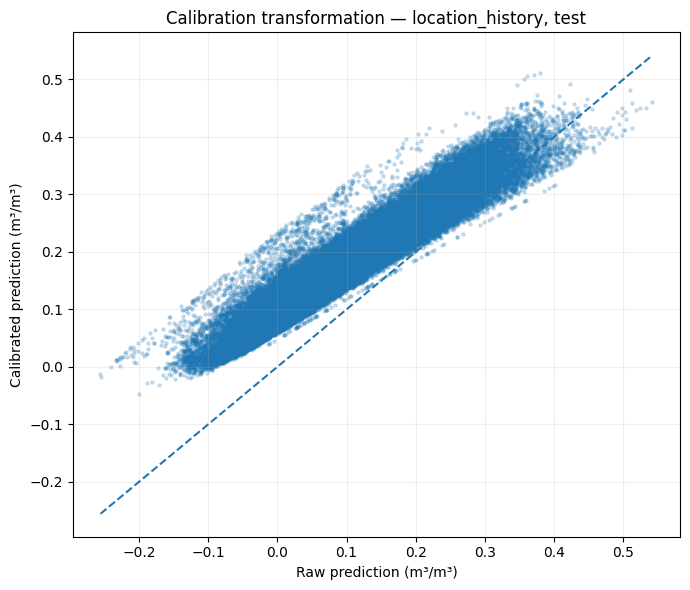

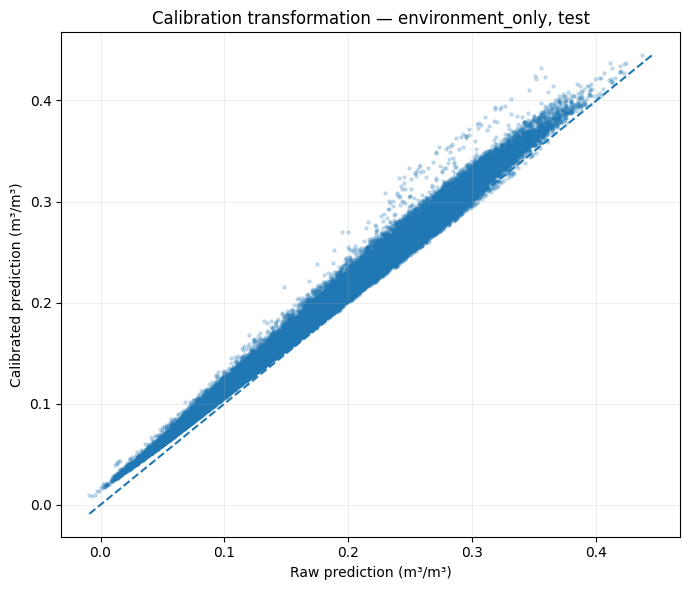

In [12]:
# 12. Calibration effects and raw-vs-calibrated scatter on the test sample
calibration_rows = []
for mode in ("location_history", "environment_only"):
    d = METRICS[(METRICS.task_mode == mode) & (METRICS.split == "test")].set_index("variant")
    calibration_rows.append({
        "task_mode": mode,
        "raw_mae": d.loc["raw", "mae_m3_m3"],
        "calibrated_mae": d.loc["calibrated", "mae_m3_m3"],
        "mae_change_calibrated_minus_raw": d.loc["calibrated", "mae_m3_m3"] - d.loc["raw", "mae_m3_m3"],
        "raw_rmse": d.loc["raw", "rmse_m3_m3"],
        "calibrated_rmse": d.loc["calibrated", "rmse_m3_m3"],
        "rmse_change_calibrated_minus_raw": d.loc["calibrated", "rmse_m3_m3"] - d.loc["raw", "rmse_m3_m3"],
        "calibrated_bias": d.loc["calibrated", "bias_m3_m3"],
        "anchor_rmse": d.loc["SMAP_anchor", "rmse_m3_m3"],
    })
CALIBRATION_SUMMARY = pd.DataFrame(calibration_rows)
display(CALIBRATION_SUMMARY.round(6))
CALIBRATION_SUMMARY.to_csv(TABLES_DIR / "calibration_and_anchor_comparison_test.csv", index=False)

for mode in ("location_history", "environment_only"):
    view = VIEWS[(mode, "test")]
    d = DB.execute(f"""
      SELECT y_true_m3_m3, prediction_m3_m3, raw_prediction_m3_m3, anchor_smap_m3_m3
      FROM {view}
      WHERE isfinite(y_true_m3_m3) AND isfinite(prediction_m3_m3)
      ORDER BY hash(CAST(sample_id AS VARCHAR)) LIMIT {int(PLOT_SAMPLE_PER_SPLIT)}
    """).df()
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(d.raw_prediction_m3_m3, d.prediction_m3_m3, s=5, alpha=0.2)
    lo = np.nanmin([d.raw_prediction_m3_m3.min(), d.prediction_m3_m3.min()])
    hi = np.nanmax([d.raw_prediction_m3_m3.max(), d.prediction_m3_m3.max()])
    ax.plot([lo, hi], [lo, hi], linestyle="--")
    ax.set_xlabel("Raw prediction (m³/m³)"); ax.set_ylabel("Calibrated prediction (m³/m³)")
    ax.set_title(f"Calibration transformation — {mode}, test")
    ax.grid(alpha=0.2); fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"raw_vs_calibrated_{mode}_test.png", dpi=160)
    plt.show(); plt.close(fig)

## 10) Automatically surface the main findings

This section prints a compact, data-derived report from the full exports. Treat it as a diagnostic lead, not as causal proof. For example, station outliers can reflect sensor issues, local representativeness, environmental covariates, data quality, or model limitations; the export alone cannot determine which explanation is correct.

In [13]:
# 13. Key findings and anomaly shortlist

def fmt_num(x, digits=5):
    try:
        return f"{float(x):.{digits}f}" if pd.notna(x) else "NA"
    except Exception:
        return str(x)

lines = []
lines.append("v19.5 ERROR ANALYSIS — AUTOMATIC SUMMARY")
lines.append(f"Target mode: {TARGET_MODE}")
lines.append("")
for split in ("train", "test"):
    lines.append(f"{split.upper()} full-split calibrated performance:")
    for mode in ("location_history", "environment_only"):
        r = METRICS[(METRICS.task_mode == mode) & (METRICS.split == split) & (METRICS.variant == "calibrated")].iloc[0]
        lines.append(f"  {mode}: n={int(r.n):,}, MAE={fmt_num(r.mae_m3_m3)}, RMSE={fmt_num(r.rmse_m3_m3)}, "
                     f"bias={fmt_num(r.bias_m3_m3)}, R²={fmt_num(r.r2)}")
    pr = PAIRED_METRICS[PAIRED_METRICS.split == split].iloc[0]
    lines.append(f"  matched rows={int(pr.n):,}; paired location−environment MAE={fmt_num(pr.location_minus_environment_mae)}; "
                 f"location win rate={fmt_num(pr.location_win_pct,2)}%")
    lines.append("")

if len(PAIRED_TEST_STATION):
    better_lh = int((PAIRED_TEST_STATION.location_minus_environment_rmse < 0).sum())
    better_eo = int((PAIRED_TEST_STATION.location_minus_environment_rmse > 0).sum())
    tied = int((PAIRED_TEST_STATION.location_minus_environment_rmse == 0).sum())
    lines.append(f"Matched test stations with >= {MIN_STATION_ROWS} rows: {len(PAIRED_TEST_STATION):,}")
    lines.append(f"  Lower station RMSE: location_history={better_lh}, environment_only={better_eo}, ties={tied}")
    lines.append("  Largest location-history gains (most negative RMSE delta):")
    for r in PAIRED_TEST_STATION.nsmallest(5, "location_minus_environment_rmse").itertuples():
        lines.append(f"    {r.network}:{r.station_id} n={r.n} ΔRMSE={fmt_num(r.location_minus_environment_rmse)}")
    lines.append("  Largest environment-only gains (most positive RMSE delta):")
    for r in PAIRED_TEST_STATION.nlargest(5, "location_minus_environment_rmse").itertuples():
        lines.append(f"    {r.network}:{r.station_id} n={r.n} ΔRMSE={fmt_num(r.location_minus_environment_rmse)}")

lines.append("")
lines.append("Interpretation reminders:")
lines.append("- Use test metrics as the primary generalisation comparison.")
lines.append("- Prefer paired metrics when judging the value of location history.")
lines.append("- Check overlap counts: a small matched subset may not represent the full test set.")
lines.append("- Investigate station/network outliers before drawing regional conclusions.")
lines.append("- Check residual sign: positive means overprediction; negative means underprediction.")
lines.append("- The notebook is diagnostic; it does not establish the cause of any error pattern.")

SUMMARY_TEXT = "\n".join(lines)
print(SUMMARY_TEXT)
(OUTPUT_DIR / "automatic_findings.txt").write_text(SUMMARY_TEXT, encoding="utf-8")

v19.5 ERROR ANALYSIS — AUTOMATIC SUMMARY
Target mode: direct

TRAIN full-split calibrated performance:
  location_history: n=2,216,784, MAE=0.03544, RMSE=0.04836, bias=-0.00065, R²=0.83079
  environment_only: n=2,544,038, MAE=0.05892, RMSE=0.07580, bias=0.00497, R²=0.57113
  matched rows=1,768,579; paired location−environment MAE=-0.02424; location win rate=70.11%

TEST full-split calibrated performance:
  location_history: n=905,248, MAE=0.04854, RMSE=0.06594, bias=0.00123, R²=0.65341
  environment_only: n=644,716, MAE=0.06794, RMSE=0.08626, bias=0.00405, R²=0.47046
  matched rows=182,528; paired location−environment MAE=-0.01731; location win rate=62.62%

Matched test stations with >= 10 rows: 201
  Lower station RMSE: location_history=138, environment_only=63, ties=0
  Largest location-history gains (most negative RMSE delta):
    SNOTEL:SNOTEL__Mt._Ryan n=585 ΔRMSE=-0.10383
    Ru_CFR:Ru_CFR__Fyodorovskoye_dry_spruce_stand n=419 ΔRMSE=-0.10300
    REMEDHUS:REMEDHUS__El_Coto n=574 Δ

1929

## 11) Export all analysis outputs

The outputs include the full metric tables (CSV), plots (PNG), and a machine-readable run summary. The original exports are never modified. Re-running this notebook overwrites the analysis outputs in `error_analysis_results_v19_5/` only.

In [14]:
# 14. Save a reproducibility manifest and list generated outputs
manifest = {
    "analysis_created_local": pd.Timestamp.now().isoformat(),
    "base_dir": str(BASE_DIR),
    "target_mode": TARGET_MODE,
    "export_dirs": {k: str(v) for k, v in EXPORT_DIRS.items()},
    "prediction_files": {
        mode: {split: str(folder / "predictions" / f"{split}_predictions.parquet")
               for split in ("train", "test")}
        for mode, folder in EXPORT_DIRS.items()
    },
    "settings": {
        "min_station_rows": MIN_STATION_ROWS,
        "plot_sample_per_split": PLOT_SAMPLE_PER_SPLIT,
        "spatial_grid_degrees": SPATIAL_GRID_DEGREES,
    },
    "tables": sorted(p.name for p in TABLES_DIR.glob("*.csv")),
    "plots": sorted(p.name for p in PLOTS_DIR.glob("*.png")),
}
(OUTPUT_DIR / "analysis_manifest.json").write_text(json.dumps(manifest, indent=2, default=str), encoding="utf-8")

print("\nANALYSIS COMPLETE")
print("Outputs:", OUTPUT_DIR)
print("CSV tables:", len(list(TABLES_DIR.glob('*.csv'))))
print("PNG plots:", len(list(PLOTS_DIR.glob('*.png'))))
print("Key files:")
for p in sorted(OUTPUT_DIR.glob("*")):
    print(" -", p.name)
print("\nDuckDB remains in memory for this notebook session. Close it with DB.close() when finished.")


ANALYSIS COMPLETE
Outputs: /home/mayur/Code/UG_SM/error_analysis_results_v19_5
CSV tables: 14
PNG plots: 21
Key files:
 - analysis_manifest.json
 - automatic_findings.txt
 - duckdb_tmp
 - plots
 - tables

DuckDB remains in memory for this notebook session. Close it with DB.close() when finished.


## How to read the most important outputs

1. **`overall_metrics.csv`** — complete train/test MAE, RMSE, bias, R², and correlation for calibrated, raw, and SMAP-anchor predictions.
2. **`paired_overlap.csv` + `paired_metrics.csv`** — the fairest overall comparison of the two model modes on exactly the same observations.
3. **`paired_station_comparison.csv`** — which stations benefit from location history and which do not.
4. **`station_metrics_all.csv`** — full per-station performance for both models and both splits.
5. **`spatial_grid_metrics_test.csv`** — coarse spatial error patterns.
6. **`monthly_metrics_test.csv`, `annual_metrics_test.csv`, `target_moisture_bin_metrics_test.csv`** — time- and moisture-dependent error patterns.
7. **`automatic_findings.txt`** — short data-derived summary and outlier shortlist.

### Suggested interpretation sequence

Start with test RMSE/MAE. Then inspect the paired comparison and the overlap percentage. Next inspect the paired station RMSE-difference map, the worst-station tables, and network summaries. Finally inspect temporal and moisture-regime plots. A model that wins overall but loses badly at a subset of stations may need targeted data-quality checks or a more careful treatment of station heterogeneity.